# Credit Card Fraud Detection

In [1]:
# Importing Libraries
import warnings
warnings.filterwarnings('ignore')
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from xgboost import XGBClassifier
from sklearn.metrics import classification_report 
from sklearn.preprocessing import LabelEncoder 
from sklearn.model_selection import train_test_split
from sklearn.metrics import average_precision_score, precision_recall_curve
from sklearn.metrics import ConfusionMatrixDisplay

# Data Collection
df_train = pd.read_csv("Fraud_Train_Data.csv")
df_test = pd.read_csv("Fraud_Test_Data.csv")
df = pd.concat([df_train, df_test], ignore_index=True)

display(df.head())

,Unnamed: 0,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,...,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,...,36.0788,-81.1781,3495,"Psychologist, counselling",1988-03-09,0b242abb623afc578575680df30655b9,1325376018,36.011293,-82.048315,0
1,1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,...,48.8878,-118.2105,149,Special educational needs teacher,1978-06-21,1f76529f8574734946361c461b024d99,1325376044,49.159047,-118.186462,0
2,2,2019-01-01 00:00:51,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,...,42.1808,-112.2620,4154,Nature conservation officer,1962-01-19,a1a22d70485983eac12b5b88dad1cf95,1325376051,43.150704,-112.154481,0
3,3,2019-01-01 00:01:16,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,...,46.2306,-112.1138,1939,Patent attorney,1967-01-12,6b849c168bdad6f867558c3793159a81,1325376076,47.034331,-112.561071,0
4,4,2019-01-01 00:03:06,375534208663984,fraud_Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,408 Bradley Rest,...,38.4207,-79.4629,99,Dance movement psychotherapist,1986-03-28,a41d7549acf90789359a9aa5346dcb46,1325376186,38.674999,-78.632459,0


In [2]:
# Data Preprocessing 
df.drop(columns = ['Unnamed: 0', 'cc_num', 'merchant','first', 'last', 'street', 'city', 
                   'state', 'zip', 'city_pop', 'job', 'trans_num', 'unix_time'], inplace=True)

df['trans_date_trans_time'] = pd.to_datetime(df['trans_date_trans_time'])
df['dob'] = pd.to_datetime(df['dob'])
df['trans_hour'] = df['trans_date_trans_time'].dt.hour
df['trans_day'] = df['trans_date_trans_time'].dt.day
df['trans_month'] = df['trans_date_trans_time'].dt.month
df['age'] = (df['trans_date_trans_time'] - df['dob']).dt.days // 365

def haversine(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat / 2.0)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2.0)**2
    c = 2 * np.arcsin(np.sqrt(a))
    km = 6371 * c
    return km

df["distance_km"] = haversine(df["lat"], df["long"], df["merch_lat"], df["merch_long"])

In [3]:
# Categorical Feature Encoding 
cat_cols = ["category", "gender"]
for col in cat_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])  
    
df = df.drop(columns=['trans_date_trans_time', 'dob'])

# Train Test Split
X = df.drop(columns=["is_fraud"])
y = df["is_fraud"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.42, random_state = 42
)


Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.99      1.00    773965
           1       0.44      0.95      0.60      4041

    accuracy                           0.99    778006
   macro avg       0.72      0.97      0.80    778006
weighted avg       1.00      0.99      0.99    778006

PR-AUC: 0.9151


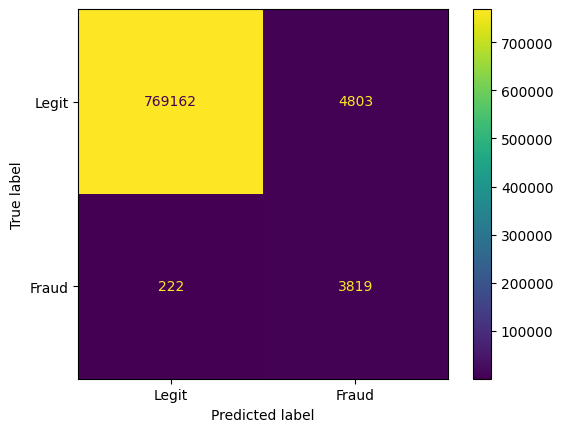

In [4]:
# Model Training
model = XGBClassifier(
    scale_pos_weight=(len(y_train) - sum(y_train)) / sum(y_train), 
    random_state=42
)
model.fit(X_train, y_train)


# Model Evaluation
y_pred = model.predict(X_test)
print("\nClassification Report:\n", classification_report(y_test, y_pred))

y_pred_proba = model.predict_proba(X_test)[:, 1]
pr_auc = average_precision_score(y_test, y_pred_proba)
print(f"PR-AUC: {pr_auc:.4f}")

ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, display_labels=["Legit", "Fraud"])

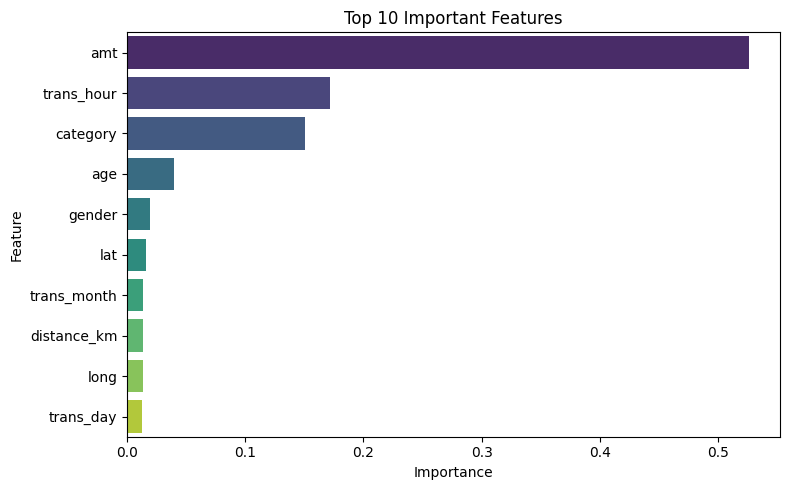

Model saved successfully.


In [5]:
# Feature Importance 
importance = pd.DataFrame({"Feature": X.columns, "Importance": model.feature_importances_})
importance = importance.sort_values(by="Importance", ascending=False)
plt.figure(figsize=(8, 5))
sns.barplot(data=importance.head(10), x="Importance", y="Feature", palette="viridis")
plt.title("Top 10 Important Features")
plt.tight_layout()
plt.show()


# Model Serialization
joblib.dump(model, "Credit_Card_Fraud_Detection.pkl")
print("Model saved successfully.")